# EDA — Ghost Data Still Exists (HackerRank Orchestrate, Oct 2026)

**Purpose:** a planning document, not a deliverable. It profiles the CSV inputs, maps how they relate to each other, flags deviations and anomalies, and lists the non-English requests.

**Order of work:** the 32 sample cases come first, because their answers are known. The 518 evaluation requests follow.

**Scope:** the CSV files under `dataset/`. Evidence files are touched only through the manifest and a plain-text identifier scan. A full evidence deep-dive is a separate step.

Run this notebook from the `docs/` folder. It reads `../dataset/`.

In [1]:
import pandas as pd, numpy as np, json, re, hashlib, collections, os
import matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 160)
pd.set_option('display.max_rows', 120); pd.set_option('display.max_columns', 20)
DS = '../dataset'
rd = lambda f: pd.read_csv(os.path.join(DS, f))
req   = rd('deletion_requests.csv')
sreq  = rd('sample_deletion_requests.csv')
sout  = rd('sample_output.csv')
ui    = rd('user_identities.csv')
audit = rd('user_audit_log.csv')
act   = rd('system_activity.csv')
rules = rd('deletion_rules.csv')
ef    = rd('evidence_files.csv')
tmpl  = rd('output.csv')
inv = pd.DataFrame([(n, *x.shape, x.isna().sum().sum(), x.duplicated().sum()) for n, x in
      [('deletion_requests',req),('sample_deletion_requests',sreq),('sample_output',sout),('user_identities',ui),
       ('user_audit_log',audit),('system_activity',act),('deletion_rules',rules),('evidence_files',ef),('output (template)',tmpl)]],
      columns=['file','rows','cols','null_cells','dup_rows'])
inv

,file,rows,cols,null_cells,dup_rows
0,deletion_requests,518,7,0,0
1,sample_deletion_requests,32,7,0,0
2,sample_output,32,3,0,0
3,user_identities,850,6,0,0
4,user_audit_log,306,6,0,0
5,system_activity,4011,8,0,0
6,deletion_rules,15,4,0,0
7,evidence_files,94,4,0,0
8,output (template),0,3,0,0


## 1. Keys and schema

| File | Key | Joins to |
|---|---|---|
| `deletion_requests` / `sample_deletion_requests` | `case_id` | `email` → `user_identities.email` **or** a historical email in `user_audit_log.old_value` |
| `user_identities` | `user_id` | `user_audit_log.user_id`; `email_hash` = sha256(email) |
| `user_audit_log` | `audit_id` | `user_id`. It records old/new values for `email`, `email_hash` and `phone` |
| `system_activity` | `activity_id` | `resource_id` (prefix such as `account_`, `search_`); `source_system` → `target_system` |
| `deletion_rules` | `rule_id` | `data_category` → the category of a record found in evidence |
| `evidence_files` | `file_id` | `file_path` → `evidence/...` (citable as `evidence_id`) |
| `sample_output` | `case_id` | `steps_json[*].evidence_id` → `file_id` (also `activity_id` / `audit_id` per spec) |

In [2]:
print('case_id overlap sample vs eval:', set(sreq.case_id) & set(req.case_id))
print('sample ids:', sreq.case_id.min(), '..', sreq.case_id.max(), '| eval ids:', req.case_id.iloc[0], '..', req.case_id.iloc[-1])
print('output template rows:', len(tmpl), '| columns:', list(tmpl.columns))
lex = sorted(req.case_id); num = sorted(req.case_id, key=lambda c: int(c.split('_')[1]))
print('file order == numeric order:', list(req.case_id) == num, '| file order == lexical order:', list(req.case_id) == lex)
print('first 5 lexical:', lex[:5])
print('sample_output order == sample request order:', list(sout.case_id) == list(sreq.case_id))

case_id overlap sample vs eval: set()
sample ids: case_01 .. case_32 | eval ids: case_33 .. case_550
output template rows: 0 | columns: ['case_id', 'deletion_status', 'steps_json']
file order == numeric order: True | file order == lexical order: False
first 5 lexical: ['case_100', 'case_101', 'case_102', 'case_103', 'case_104']
sample_output order == sample request order: True


> **Ordering note:** the file is in *numeric* case order (`case_33 … case_550`). A plain string sort would give `case_100, case_101, …`. The spec says to sort by `case_id`. The canonical order is most likely the numeric order of the input file, and the sample output also uses numeric order (`case_01 … case_32`). **We should keep the exact row order of `deletion_requests.csv`.** This is a decision to confirm.

## 2. Sample data (32 cases with known answers)

In [3]:
S = sreq.merge(sout, on='case_id')
print(pd.crosstab(S.reported_status, S.deletion_status, margins=True))

deletion_status     COMPLETE  INCOMPLETE  All
reported_status                              
COMPLETE                   6          11   17
NOT_STARTED                3           7   10
PARTIALLY_COMPLETE         1           4    5
All                       10          22   32


**Observation:** `reported_status` predicts almost nothing. 11 of 17 reported `COMPLETE` are actually `INCOMPLETE`. 3 `NOT_STARTED` and 1 `PARTIALLY_COMPLETE` are actually `COMPLETE`. There are **no `NOT_APPLICABLE` samples**, so the non-deletion path has no labelled example.

In [4]:
steps = []
for r in S.itertuples():
    for st in json.loads(r.steps_json):
        steps.append({**st, 'case_id': r.case_id, 'status': r.deletion_status})
ST = pd.DataFrame(steps)
print('total steps', len(ST), '| per case:', ST.groupby('case_id').size().describe().round(2).to_dict())
print(ST.groupby(['status','phase','operation','state']).size().to_string())

total steps 193 | per case: {'count': 32.0, 'mean': 6.03, 'std': 3.64, 'min': 1.0, '25%': 3.75, '50%': 5.0, '75%': 8.0, 'max': 14.0}
status      phase         operation                  state     
COMPLETE    VERIFICATION  VERIFY_DATA_FLOW_DISABLED  DISABLED       3
                          VERIFY_RECORD_ABSENT       ABSENT        10
                          VERIFY_RECORD_ANONYMIZED   ANONYMIZED     7
                          VERIFY_RECORD_PRESENT      PRESENT        7
                          VERIFY_RECORD_REDACTED     REDACTED       4
                          VERIFY_RESTORE_BLOCKED     BLOCKED        3
INCOMPLETE  FINDING       REPORT_ACTIVE_DATA_FLOW    ACTIVE         6
                          REPORT_EXPOSED_PII         PRESENT       11
                          REPORT_REMAINING_RECORD    PRESENT       21
                          REPORT_RESTORE_RISK        ACTIVE         3
            REMEDIATION   ANONYMIZE_RECORD           ANONYMIZED     5
                          BLOCK_R

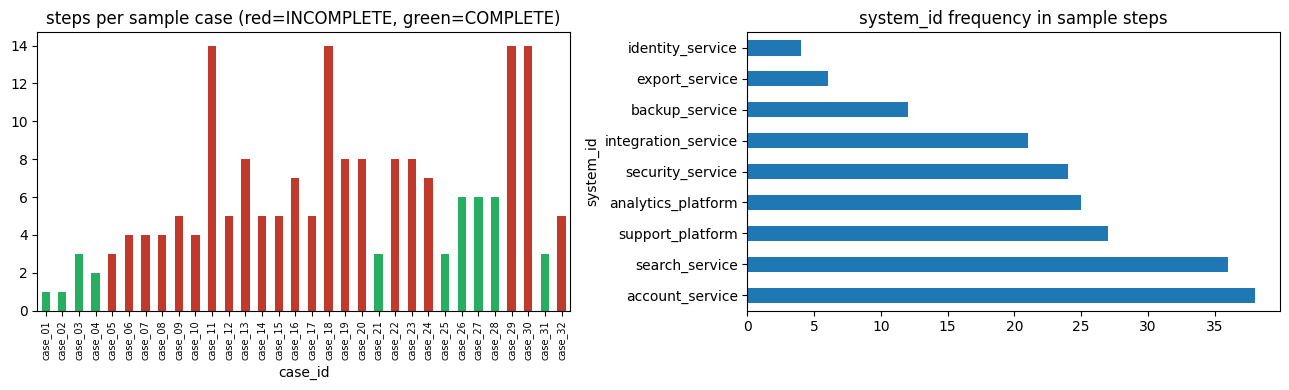

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ST.groupby('case_id').size().reindex(S.case_id).plot.bar(ax=ax[0], color=['#c0392b' if s=='INCOMPLETE' else '#27ae60' for s in S.deletion_status])
ax[0].set_title('steps per sample case (red=INCOMPLETE, green=COMPLETE)'); ax[0].tick_params(axis='x', labelsize=7)
ST.system_id.value_counts().plot.barh(ax=ax[1]); ax[1].set_title('system_id frequency in sample steps')
plt.tight_layout(); plt.show()

### 2.1 Structural invariants in the sample answers

In [6]:
OP_ORDER = ['REPORT_REMAINING_RECORD','REPORT_EXPOSED_PII','REPORT_ACTIVE_DATA_FLOW','REPORT_RESTORE_RISK',
            'DISABLE_DATA_FLOW','BLOCK_RESTORE','DELETE_RECORD','REDACT_RECORD','ANONYMIZE_RECORD',
            'VERIFY_RECORD_ABSENT','VERIFY_RECORD_PRESENT','VERIFY_RECORD_REDACTED','VERIFY_RECORD_ANONYMIZED',
            'VERIFY_DATA_FLOW_DISABLED','VERIFY_RESTORE_BLOCKED']
PH = {'FINDING':0,'REMEDIATION':1,'VERIFICATION':2}
chk = []
for cid, g in ST.groupby('case_id', sort=False):
    g = g.sort_values('step_no'); stt = g.status.iloc[0]; ev = g.evidence_id.fillna('')
    key = list(zip(g.phase.map(PH), g.operation.map(OP_ORDER.index), g.system_id, g.resource_id))
    chk.append(dict(case_id=cid,
        consecutive = list(g.step_no) == list(range(1, len(g)+1)),
        sorted_by_spec = key == sorted(key),
        complete_only_verif = (stt != 'COMPLETE') or set(g.phase) == {'VERIFICATION'},
        complete_all_cited = (stt != 'COMPLETE') or (ev != '').all(),
        incomplete_findings_cited = (stt != 'INCOMPLETE') or (ev[g.phase=='FINDING'] != '').all(),
        incomplete_future_blank = (stt != 'INCOMPLETE') or (ev[g.phase!='FINDING'] == '').all()))
chk = pd.DataFrame(chk); print(chk.drop(columns='case_id').all())
print('violations:'); print(chk[~chk.drop(columns='case_id').all(axis=1)])

consecutive                  True
sorted_by_spec               True
complete_only_verif          True
complete_all_cited           True
incomplete_findings_cited    True
incomplete_future_blank      True
dtype: bool
violations:
Empty DataFrame
Columns: [case_id, consecutive, sorted_by_spec, complete_only_verif, complete_all_cited, incomplete_findings_cited, incomplete_future_blank]
Index: []


In [7]:
# Cited evidence: which kind of id, which files, captured before audit_at?
cited = ST[ST.evidence_id.fillna('') != ''].merge(ef, left_on='evidence_id', right_on='file_id', how='left').merge(S[['case_id','audit_at']], on='case_id')
print('cited id kinds:', cited.evidence_id.str.extract(r'^([a-z]+)_')[0].value_counts().to_dict())
cited['ext'] = cited.file_path.str.extract(r'\.(\w+)$')[0]
print('cited file types:', cited.ext.value_counts().to_dict())
print('cited captured_at <= audit_at:', (cited.captured_at <= cited.audit_at).all())
print('distinct files cited:', cited.evidence_id.nunique(), 'of', len(ef))
cited.groupby(['evidence_id','file_path']).size().sort_values(ascending=False).head(15)

cited id kinds: {'evidence': 75}
cited file types: {'json': 42, 'log': 15, 'sql': 10, 'txt': 7, 'pdf': 1}
cited captured_at <= audit_at: True
distinct files cited: 13 of 94


evidence_id  file_path                                                         
evidence_92  evidence/records/service_resource_export_20260915_114455.json         36
evidence_94  evidence/logs/resource_lookup_trace_20260926_103856.log                9
evidence_03  evidence/records/customer_account_handover_20261001.txt                7
evidence_01  evidence/logs/service_events_ap_south_20260915.log                     5
evidence_05  evidence/databases/customer_data_read_replica_20260921.sql             4
evidence_54  evidence/databases/customer_accounts_failover_replica_20260902.sql     4
evidence_51  evidence/records/customer_data_snapshot_bundle_20260915.json           4
evidence_56  evidence/records/customer_analytics_report_20260907.json               1
evidence_57  evidence/databases/customer_search_primary_20260910.sql                1
evidence_59  evidence/records/customer_export_jobs_20260914.json                    1
evidence_58  evidence/documents/delivery_correction_attachme

In [8]:
# Finding -> remediation -> verification pairing per resource (INCOMPLETE cases)
inc = ST[ST.status=='INCOMPLETE']
trip = inc.pivot_table(index=['case_id','system_id','resource_id'], columns='phase', values='operation', aggfunc=lambda x: '|'.join(x)).fillna('-')
print(trip.value_counts().to_string())

FINDING                  REMEDIATION        VERIFICATION             
REPORT_REMAINING_RECORD  DELETE_RECORD      VERIFY_RECORD_ABSENT         21
-                        -                  VERIFY_RECORD_ABSENT         19
                                            VERIFY_RECORD_PRESENT        17
REPORT_ACTIVE_DATA_FLOW  DISABLE_DATA_FLOW  VERIFY_DATA_FLOW_DISABLED     6
REPORT_EXPOSED_PII       REDACT_RECORD      VERIFY_RECORD_REDACTED        6
                         ANONYMIZE_RECORD   VERIFY_RECORD_ANONYMIZED      5
REPORT_RESTORE_RISK      BLOCK_RESTORE      VERIFY_RESTORE_BLOCKED        3


In [9]:
# Retained records that are only verified (no finding / remediation)
ret = ST[ST.operation=='VERIFY_RECORD_PRESENT'][['case_id','status','system_id','resource_id','evidence_id']]
print(ret.system_id.value_counts().to_dict()); ret.head(12)

{'security_service': 24}


,case_id,status,system_id,resource_id,evidence_id
3,case_03,COMPLETE,security_service,audit_record_2016,evidence_94
25,case_09,INCOMPLETE,security_service,audit_record_4902,
41,case_11,INCOMPLETE,security_service,audit_record_9394,
49,case_12,INCOMPLETE,security_service,audit_record_2945,
57,case_13,INCOMPLETE,security_service,audit_record_4816,
61,case_14,INCOMPLETE,security_service,audit_record_987,
66,case_15,INCOMPLETE,security_service,audit_record_1596,
74,case_16,INCOMPLETE,security_service,audit_record_9528,
78,case_17,INCOMPLETE,security_service,audit_record_1797,
90,case_18,INCOMPLETE,security_service,audit_record_6645,


In [10]:
# Full sample answer listing (compact)
for r in S.itertuples():
    print(f'{r.case_id} {r.reported_status:>18} -> {r.deletion_status}')
    for st in json.loads(r.steps_json):
        print(f"   {st['step_no']:>2} {st['phase']:<12} {st['operation']:<26} {st['system_id']:<20} {st['resource_id']:<18} {st['evidence_id']}")

case_01           COMPLETE -> COMPLETE
    1 VERIFICATION VERIFY_RECORD_ABSENT       account_service      account_001        evidence_54
case_02 PARTIALLY_COMPLETE -> COMPLETE
    1 VERIFICATION VERIFY_RECORD_ABSENT       account_service      account_002        evidence_54
case_03           COMPLETE -> COMPLETE
    1 VERIFICATION VERIFY_RECORD_ABSENT       account_service      account_7566       evidence_94
    2 VERIFICATION VERIFY_RECORD_PRESENT      security_service     audit_record_2016  evidence_94
    3 VERIFICATION VERIFY_RECORD_ANONYMIZED   analytics_platform   analytics_9406     evidence_94
case_04           COMPLETE -> COMPLETE
    1 VERIFICATION VERIFY_RECORD_ABSENT       account_service      account_004        evidence_54
    2 VERIFICATION VERIFY_RECORD_ANONYMIZED   analytics_platform   analytics_901      evidence_56
case_05           COMPLETE -> INCOMPLETE
    1 FINDING      REPORT_REMAINING_RECORD    account_service      account_005        evidence_54
    2 REMEDIATION  

### 2.2 What the samples tell us
* Every structural rule in the spec holds: steps numbered consecutively, ordered by phase → operation-table order → `system_id` → `resource_id`, `COMPLETE` cases contain only cited verifications, and `INCOMPLETE` future steps have a blank `evidence_id`. The invariant cell above shows any exception.
* In the samples, citations are **always `evidence_*` file ids** and never `activity_*` or `audit_*`. Every cited file was captured at or before `audit_at`.
* Findings pair with remediation and verification: a remaining record leads to DELETE then VERIFY_ABSENT, exposed PII leads to REDACT or ANONYMIZE then the matching VERIFY, an active flow leads to DISABLE then VERIFY_DISABLED, and a restore risk leads to BLOCK then VERIFY_BLOCKED.
* Retained records (security audit, legal hold, backups, tombstones) appear as `VERIFY_RECORD_PRESENT` and similar checks with no finding.

## 3. Request text: language and intent

In [11]:
from langdetect import detect, DetectorFactory; DetectorFactory.seed = 0
for x in (sreq, req): x['lang'] = x.request_text.apply(detect)
print('sample:', sreq.lang.value_counts().to_dict()); print('eval  :', req.lang.value_counts().to_dict())
sreq[sreq.lang!='en'][['case_id','lang','request_text']]

sample: {'en': 29, 'es': 1, 'fr': 1, 'ja': 1}
eval  : {'en': 456, 'pt': 14, 'ko': 12, 'es': 12, 'ja': 12, 'fr': 12}


,case_id,lang,request_text
1,case_02,es,"Intenté eliminar mi cuenta ayer, pero la página terminó mostrando un error. ¿Pueden comprobar si todavía queda algún dato y completar la eliminación si hace..."
2,case_03,fr,Je demande la suppression définitive du compte associé à cette adresse e-mail. Veuillez examiner les identifiants actuels et antérieurs conformément à votre...
13,case_14,ja,このメールアドレスに関連するアカウントの完全な削除を依頼します。 プライバシー手続きに従い、現在および過去の識別情報を確認してください。 確認が完了したら結果をお知らせください。


In [12]:
# Non-English requests: eval set (each language uses ONE fixed template)
ne = req[req.lang!='en']
print(ne.groupby('lang').agg(n=('case_id','size'), templates=('request_text','nunique')))
for lang, g in ne.groupby('lang'):
    print(f"\n[{lang}] {len(g)} cases: {', '.join(g.case_id)}\n   text: {g.request_text.iloc[0]}")

       n  templates
lang               
es    12          1
fr    12          1
ja    12          1
ko    12          1
pt    14          1

[es] 12 cases: case_69, case_108, case_147, case_186, case_225, case_264, case_303, case_342, case_381, case_420, case_459, case_498
   text: Solicito la eliminación permanente de la cuenta asociada a este correo. Revisen los identificadores actuales y anteriores según su política de privacidad. Por favor, confirmen el resultado cuando termine la revisión.

[fr] 12 cases: case_84, case_123, case_162, case_201, case_240, case_279, case_318, case_357, case_396, case_435, case_474, case_513
   text: Je demande la suppression définitive du compte associé à cette adresse e-mail. Veuillez examiner les identifiants actuels et antérieurs conformément à votre procédure de confidentialité. Merci de confirmer le résultat une fois la vérification terminée.

[ja] 12 cases: case_78, case_117, case_156, case_195, case_234, case_273, case_312, case_351, case_390,

| Lang | Template (meaning) |
|---|---|
| pt | "I request permanent deletion of the account linked to this e-mail. Check current and previous identifiers per the privacy process. Please confirm the result when the review ends." |
| es | Same meaning, Spanish |
| fr | Same meaning, French |
| ja | Same meaning, Japanese |
| ko | Same meaning, Korean |

All 62 non-English requests in the eval set are **deletion requests**, and each language uses a single fixed template. The sample set has 3 (es, fr, ja). Note that the template explicitly asks to check **current and previous identifiers**.

In [13]:
# Intent templates: first sentence of each request
split = lambda t: [s for s in re.split(r'(?<=[.!?。])\s*', t) if s]
req['s1'] = req.request_text.apply(lambda t: split(t)[0])
vc = req.s1.value_counts(); print('distinct first sentences:', len(vc), '| distinct full texts:', req.request_text.nunique())
vc.to_frame('n')

distinct first sentences: 27 | distinct full texts: 375


,n
s1,
Please treat this message as a request for permanent account deletion.,52
I would like to submit a request to delete this account and its personal data.,49
I am requesting deletion of the account registered to this email address.,46
Please erase the account linked to this email address.,45
I am asking you to remove my account and the personal information linked to it.,39
I no longer use this account and would like it permanently deleted.,37
Please permanently delete the account associated with this email address.,37
Please process a permanent account-deletion request for this email address.,31
Please close my account and process the associated personal-data deletion.,29


In [14]:
# Requests that do NOT authorise deletion (single-occurrence templates)
nonDel = req[req.s1.map(vc) == 1][['case_id','email','reported_status','request_text']]
print(len(nonDel), 'non-deletion requests; reported_status:', nonDel.reported_status.value_counts().to_dict()); nonDel

10 non-deletion requests; reported_status: {'NOT_STARTED': 10}


,case_id,email,reported_status,request_text
500,case_533,haruka-kato@gmail.com,NOT_STARTED,The mobile number on my profile is out of date. Please replace it with the new one and leave the account active.
501,case_534,mlim7637@gmail.com,NOT_STARTED,"Please stop the promotional emails. I still need the account and my order history, so I am not asking for deletion."
502,case_535,gabriel.l5556@outlook.com,NOT_STARTED,I'd like to download my account information in a portable format. Please keep the account as it is.
503,case_536,aditi.mehta@outlook.com,NOT_STARTED,I can't access my profile and need help resetting the login. Do not close the account.
504,case_537,l.alvarez94@yahoo.com,NOT_STARTED,My surname is misspelled on the account. Can you correct it without removing any of my records?
505,case_538,morgan.amelia@icloud.com,NOT_STARTED,Please remove me from marketing lists only. I still want receipts and service messages for this account.
506,case_539,leonie-rousseau@proton.me,NOT_STARTED,"Can you tell me what personal information you hold about me? This is an information request, not a request to erase it."
507,case_540,ieriksen5151@fastmail.com,NOT_STARTED,I need a copy of last year's invoices for my records. Please leave my profile and purchase history in place.
508,case_541,elena.h3070@zoho.com,NOT_STARTED,Please change the email address used for this account. I want to continue using the service.
509,case_542,omar.nasser@gmail.com,NOT_STARTED,"Could you send me a copy of the information held on my account? I still use it, so please don't delete or change anything."


**Intent findings**
* 508 deletion requests come from 17 first-sentence templates (12 English and 5 non-English). The 2nd and 3rd sentences are generic boilerplate ("please confirm…", "include current/earlier identifiers…").
* **10 non-deletion requests** (`case_533`–`case_542`) cover a phone update, a marketing opt-out, a data export or portability request, a login reset, a name correction, an access request, an invoice copy and an email change. All are `NOT_STARTED`, and several explicitly say *"not asking for deletion"*. They should produce `NOT_APPLICABLE` with `[]`.
* Traps to handle: *"Please remove me from marketing lists only"* contains "remove" and *"not a request to erase it"* contains "erase". A keyword classifier would misfire, so we need negation and scope awareness, either from an LLM or from rules plus an LLM.
* The sample request texts are richer and more varied, and they carry **scenario hints**: old email, search result, integration, backup, support attachment, export link, tombstone, a similar-email decoy, "as it stood when reviewed". The eval texts are generic, so the solution **cannot rely on request text** to know which systems to inspect.

## 4. Identity relationships (`user_identities` ↔ `user_audit_log` ↔ requests)

In [15]:
ui['sha'] = ui.email.str.lower().apply(lambda e: hashlib.sha256(e.encode()).hexdigest())
print('email_hash == sha256(lower(email)) for all users:', (ui.sha == ui.email_hash).all())
print('unique user_id/email/phone/hash:', ui.user_id.is_unique, ui.email.is_unique, ui.phone.is_unique, ui.email_hash.is_unique)
print('user_id range:', ui.user_id.iloc[0], '..', ui.user_id.iloc[-1], '| id digit widths:', ui.user_id.str.extract(r'(\d+)')[0].str.len().value_counts().to_dict())
print('non-ASCII names:', ui.name.apply(lambda v: not v.isascii()).sum())
print('duplicate NAMES (distinct people sharing a name):'); ui[ui.name.duplicated(keep=False)].sort_values('name')[['user_id','name','email']]

email_hash == sha256(lower(email)) for all users: True
unique user_id/email/phone/hash: True True True True
user_id range: user_01 .. user_850 | id digit widths: {3: 751, 2: 99}
non-ASCII names: 102
duplicate NAMES (distinct people sharing a name):


,user_id,name,email
7,user_08,Gabriel Costa,gabriel.costa@proton.me
142,user_143,Gabriel Costa,gabriel.c7146@zoho.com
1,user_02,Mateo Ríos,mateo.rios@outlook.com
261,user_262,Mateo Ríos,mrios9507@fastmail.com
3,user_04,Thandiwe Ndlovu,thandiwe.n@gmail.com
412,user_413,Thandiwe Ndlovu,thandiwe.n5276@outlook.com


In [16]:
print(audit.field_name.value_counts().to_dict(), '| changes per user:', audit.groupby('user_id').size().value_counts().to_dict())
E = audit[audit.field_name=='email']; H = audit[audit.field_name=='email_hash']
pair = E.merge(H, on=['user_id','event_time'], suffixes=('_e','_h'))
sha = lambda v: hashlib.sha256(v.lower().encode()).hexdigest()
print('every email change has a paired hash change:', len(pair)==len(E)==len(H),
      '| hashes consistent:', (pair.old_value_e.apply(sha)==pair.old_value_h).all() and (pair.new_value_e.apply(sha)==pair.new_value_h).all())
last = audit.sort_values('event_time').groupby(['user_id','field_name']).last().reset_index()
print('latest audit new_value == current snapshot:', all(ui.set_index('user_id').loc[r.user_id, r.field_name]==r.new_value for r in last.itertuples()))
print('any old email reused by another user:', bool(set(E.old_value.str.lower()) & set(ui.email.str.lower())))
print('audit window:', audit.event_time.min(), '..', audit.event_time.max())

{'email': 107, 'email_hash': 107, 'phone': 92} | changes per user: {2: 102, 1: 91, 4: 2, 3: 1}
every email change has a paired hash change: True | hashes consistent: True
latest audit new_value == current snapshot: True
any old email reused by another user: False
audit window: 2024-12-14T16:31:44Z .. 2026-06-03T08:42:31Z


In [17]:
owner = {}
for r in E.itertuples(): owner[r.old_value.lower()] = (r.user_id, 'historical')
for r in ui.itertuples(): owner[r.email.lower()] = (r.user_id, 'current')
def resolve(x):
    x['email_norm'] = x.email.str.strip().str.lower()
    x['user_id'] = x.email_norm.map(lambda e: owner.get(e, (None,None))[0])
    x['match']   = x.email_norm.map(lambda e: owner.get(e, (None,'UNRESOLVED'))[1])
    return x
for n, x in (('sample', sreq), ('eval', req)):
    resolve(x); print(n, x.match.value_counts().to_dict(), '| uppercase emails:', (x.email != x.email.str.lower()).sum())
h = req[req.match=='historical'].merge(E.assign(email_norm=E.old_value.str.lower())[['email_norm','event_time']], on='email_norm')
print('eval historical-email requests where change < requested_at:', (h.event_time < h.requested_at).sum(), '/', len(h))
print('\nuppercase request emails:', ', '.join(req[req.email != req.email.str.lower()].case_id))

sample {'current': 29, 'historical': 3} | uppercase emails: 0
eval {'current': 418, 'historical': 100} | uppercase emails: 20
eval historical-email requests where change < requested_at: 100 / 100

uppercase request emails: case_38, case_40, case_54, case_71, case_85, case_111, case_148, case_166, case_190, case_191, case_255, case_326, case_327, case_384, case_396, case_416, case_427, case_495, case_500, case_501


In [18]:
# Users with more than one request, and users shared between sample and eval
print('eval users with >1 request:')
print(req[req.user_id.duplicated(keep=False)][['case_id','user_id','email','requested_at','audit_at','reported_status']])
ov = set(sreq.user_id) & set(req.user_id)
print('\nusers appearing in BOTH sample and eval:', ov)
pd.concat([sreq[sreq.user_id.isin(ov)].assign(set='sample'), req[req.user_id.isin(ov)].assign(set='eval')])[['set','case_id','user_id','email','match','audit_at']]

eval users with >1 request:
    case_id  user_id                    email          requested_at              audit_at reported_status
0   case_33  user_18  ingrid.dahl@outlook.com  2026-07-16T08:00:00Z  2026-07-19T13:00:00Z        COMPLETE
19  case_52  user_18  ingrid.dahl@outlook.com  2026-06-16T09:00:00Z  2026-06-19T14:00:00Z        COMPLETE

users appearing in BOTH sample and eval: {'user_07', 'user_17'}


,set,case_id,user_id,email,match,audit_at
6,sample,case_07,user_07,priya.raman@gmail.com,current,2026-09-12T08:00:00Z
16,sample,case_17,user_17,leonie.g9352@outlook.com,current,2026-09-15T12:00:00Z
13,eval,case_46,user_17,leonie.g9352@outlook.com,current,2026-03-11T08:00:00Z
28,eval,case_61,user_07,priya.raman@gmail.com,current,2026-02-14T10:00:00Z


**Identity findings**
* Identity data is internally **clean and consistent**. `email_hash` = sha256(lowercased email) for every row, every email change has a matching hash change, the latest audit value equals the current snapshot, and no email ever moves between users.
* All 550 request emails resolve to a user. **100 of 518 eval requests (19%) use a historical email**, against 3 of 32 in the samples, and the change always happened before the request. Resolving the full identifier set (current plus all old emails, hashes and phones) is mandatory.
* **20 eval emails are UPPERCASE**, so matching must be case-insensitive.
* 3 pairs of **different users share a name** (decoy risk), so name alone must never be used as a join key.
* `user_18` (ingrid.dahl@outlook.com) has **two eval requests**: `case_52` (audit 2026-06-19) and `case_33` (audit 2026-07-19). The same user is judged at two different cut-offs, so the answers can legitimately differ.
* `user_07` and `user_17` appear in **both** the sample set and the eval set at different `audit_at` values. Their sample answers are useful but not directly transferable.

## 5. `system_activity.csv` — the global event stream

In [19]:
act['prefix'] = act.resource_id.str.replace(r'_?\d+$', '', regex=True)
act['num'] = act.resource_id.str.extract(r'_(\d+)$')[0]
print('rows', len(act), '| time range', act.event_time.min(), '..', act.event_time.max())
print('sorted by time:', act.event_time.is_monotonic_increasing)
aid = act.assign(n=act.activity_id.str.extract(r'(\d+)')[0].astype(int)).sort_values('n')
prev = np.r_[aid.event_time.values[:1], aid.event_time.values[:-1]]
inv_ = aid[aid.event_time.values < prev]
print('rows whose time is earlier than the previous activity_id:', len(inv_)); inv_[['activity_id','event_time','event_type','resource_id']]

rows 4011 | time range 2026-01-04T14:56:29Z .. 2026-10-01T10:18:34Z
sorted by time: False
rows whose time is earlier than the previous activity_id: 10


,activity_id,event_time,event_type,resource_id
3999,activity_4000,2026-09-26T11:07:01Z,LINK_RESOURCE_IDENTITY,account_5762
4000,activity_4001,2026-09-01T06:07:01Z,LINK_RESOURCE_IDENTITY,search_428
4001,activity_4002,2026-08-07T08:07:01Z,LINK_RESOURCE_IDENTITY,data_flow_1121
4002,activity_4003,2026-07-13T10:07:01Z,LINK_RESOURCE_IDENTITY,analytics_7438
4003,activity_4004,2026-06-18T12:07:01Z,LINK_RESOURCE_IDENTITY,export_1260
4004,activity_4005,2026-05-24T07:07:01Z,LINK_RESOURCE_IDENTITY,support_1034
4005,activity_4006,2026-04-29T09:07:01Z,LINK_RESOURCE_IDENTITY,backup_9287
4006,activity_4007,2026-02-13T08:07:01Z,LINK_RESOURCE_IDENTITY,object_19
4008,activity_4009,2026-07-18T11:07:01Z,LINK_RESOURCE_IDENTITY,export_1842
4010,activity_4011,2026-03-10T06:07:01Z,LINK_RESOURCE_IDENTITY,tombstone_17


In [20]:
print(pd.crosstab(act.event_type, act.reported_result, margins=True))

reported_result         FAILED  PARTIAL  SUCCESS   All
event_type                                            
ANONYMIZE_RECORD            64        8      132   204
BLOCK_RESTORE                0        0       36    36
CHECK_DATA_FLOW              0        0       89    89
CHECK_RESTORE_ACCESS         0        0       28    28
CLASSIFY_REQUEST             0        0       10    10
CREATE_EXPORT                9        5      141   155
DELETE_RECORD              368      220      302   890
DISABLE_DATA_FLOW            0        0       36    36
INDEX_RECORD                32       20      348   400
LINK_RESOURCE_IDENTITY       0        0       12    12
REDACT_RECORD              117        9       47   173
REFRESH_CACHE               22       16      246   284
RESTORE_BACKUP               0        0        1     1
RETAIN_RECORD               15        6      185   206
SEND_EMAIL                  21       14      333   368
SYNC_RECORD                 20       46      381   447
UPDATE_REC

In [21]:
pd.crosstab(act.prefix, act.target_system)

target_system,account_failover_replica,account_replication_cluster,account_service,analytics_platform,archive_service,backup_service,cache_service,email_delivery_service,export_service,identity_service,integration_service,legal_service,marketing_platform,object_storage,object_store,privacy_case_management,search_service,security_service,support_platform
prefix,,,,,,,,,,,,,,,,,,,
account,1,55,980,0,0,0,0,0,0,0,0,0,0,0,0,10,0,0,0
analytics,0,0,0,566,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
audit_record,0,0,0,0,196,0,0,0,0,0,0,0,0,0,0,0,0,1,0
backup,0,0,0,0,0,65,0,0,0,0,0,0,0,0,0,0,1,0,0
cache,0,0,0,0,0,0,284,0,0,0,0,0,0,0,0,0,0,0,0
data_flow,0,0,0,0,0,0,0,0,0,0,126,0,0,0,0,0,31,0,0
email_delivery,0,0,0,0,0,0,0,368,0,0,0,0,0,0,0,0,0,0,0
export,0,0,0,0,0,0,0,0,34,0,0,0,0,0,155,0,0,0,0
legal_hold,0,0,0,0,0,0,0,0,0,0,0,10,0,0,0,0,0,0,0


In [22]:
# Message templates per event type (IDs and emails masked)
act['tmpl'] = act.details.str.replace(r'[\w.+-]+@[\w.-]+', '<EMAIL>', regex=True).str.replace(r'\b[a-z_]+_\d+\b', '<ID>', regex=True)
act.groupby(['event_type','source_system','target_system','tmpl']).size().rename('n').reset_index().sort_values(['event_type','n'], ascending=[True,False])

,event_type,source_system,target_system,tmpl,n
2,ANONYMIZE_RECORD,deletion_worker,analytics_platform,Policy action completed for <ID>.,125
0,ANONYMIZE_RECORD,deletion_worker,analytics_platform,Deletion worker received the final result for <ID> from analytics_platform.,78
1,ANONYMIZE_RECORD,deletion_worker,analytics_platform,Deletion worker reported the requested operation as completed. Target resource: <ID>.,1
3,BLOCK_RESTORE,deletion_worker,backup_service,Policy action completed for <ID>.,36
4,CHECK_DATA_FLOW,deletion_worker,integration_service,Connector status check confirmed that data flow <ID> remains enabled.,89
5,CHECK_RESTORE_ACCESS,deletion_worker,backup_service,Restore-access check confirmed that archive <ID> can still be restored.,28
6,CLASSIFY_REQUEST,privacy_intake,privacy_case_management,Privacy intake classified request for <ID> as non-deletion; no destructive action was authorized.,10
7,CREATE_EXPORT,export_service,object_store,Scheduled account export processed <ID>.,155
10,DELETE_RECORD,deletion_worker,account_service,Deletion worker submitted primary profile <ID> to account_service.,532
14,DELETE_RECORD,deletion_worker,search_service,Deletion worker received the final result for <ID> from search_service.,288


In [23]:
# Rare / special events worth reading in full
act[act.event_type.isin(['LINK_RESOURCE_IDENTITY','CLASSIFY_REQUEST','RESTORE_BACKUP'])][['activity_id','event_time','event_type','target_system','resource_id','details']]

,activity_id,event_time,event_type,target_system,resource_id,details
3386,activity_3387,2026-08-22T12:58:26Z,RESTORE_BACKUP,search_service,backup_9287,Restore job repopulated downstream resource search_4882.
3485,activity_3486,2026-08-28T11:07:25Z,CLASSIFY_REQUEST,privacy_case_management,account_2461,Privacy intake classified request for account_2461 as non-deletion; no destructive action was authorized.
3511,activity_3512,2026-08-29T10:47:38Z,CLASSIFY_REQUEST,privacy_case_management,account_2176,Privacy intake classified request for account_2176 as non-deletion; no destructive action was authorized.
3530,activity_3531,2026-08-30T10:58:51Z,CLASSIFY_REQUEST,privacy_case_management,account_9321,Privacy intake classified request for account_9321 as non-deletion; no destructive action was authorized.
3617,activity_3618,2026-09-03T11:09:05Z,CLASSIFY_REQUEST,privacy_case_management,account_6486,Privacy intake classified request for account_6486 as non-deletion; no destructive action was authorized.
3647,activity_3648,2026-09-04T10:49:18Z,CLASSIFY_REQUEST,privacy_case_management,account_7452,Privacy intake classified request for account_7452 as non-deletion; no destructive action was authorized.
3658,activity_3659,2026-09-05T11:00:31Z,CLASSIFY_REQUEST,privacy_case_management,account_5605,Privacy intake classified request for account_5605 as non-deletion; no destructive action was authorized.
3740,activity_3741,2026-09-09T11:11:44Z,CLASSIFY_REQUEST,privacy_case_management,account_7821,Privacy intake classified request for account_7821 as non-deletion; no destructive action was authorized.
3777,activity_3778,2026-09-10T10:51:57Z,CLASSIFY_REQUEST,privacy_case_management,account_5835,Privacy intake classified request for account_5835 as non-deletion; no destructive action was authorized.
3788,activity_3789,2026-09-11T11:02:11Z,CLASSIFY_REQUEST,privacy_case_management,account_1733,Privacy intake classified request for account_1733 as non-deletion; no destructive action was authorized.


In [24]:
# Resource-id numbering: short (<=3 digit) ids vs long (4 digit) ids
act['width'] = act.num.str.len()
print(pd.crosstab(act.prefix, act.width))
short = act[act.width <= 3].copy(); short['user_guess'] = 'user_' + short.num.astype(int).astype(str).str.zfill(2)
print('short ids whose number matches an existing user_id:', round(short.user_guess.isin(ui.user_id).mean(), 3))
print('events per resource_id:', act.groupby('resource_id').size().value_counts().to_dict())

width           2    3    4
prefix                     
account         0  116  930
analytics       0   60  506
audit_record    0   19  178
backup          0    7   59
cache           0   21  263
data_flow       0   14  143
email_delivery  0   33  335
export          0   19  170
legal_hold      0    2    8
marketing       0    1    0
object          1    0    0
search          0   69  621
support         0   38  387
tombstone       1    3    7
short ids whose number matches an existing user_id: 0.874
events per resource_id: {1: 3885, 2: 63}


In [25]:
cnt = short.user_guess.value_counts()
for n, x in (('sample', sreq), ('eval', req)):
    x['n_act_short'] = x.user_id.map(cnt).fillna(0).astype(int)
    print(n, 'requests by # short-id activity rows:', x.n_act_short.value_counts().sort_index().to_dict())
res_in_answers = set(ST.resource_id)
print('sample-answer resource ids found in system_activity:', len(res_in_answers & set(act.resource_id)), 'of', len(res_in_answers))
print('missing from activity:', sorted(res_in_answers - set(act.resource_id)))

sample requests by # short-id activity rows: {0: 13, 1: 9, 2: 9, 4: 1}
eval requests by # short-id activity rows: {0: 348, 1: 139, 2: 29, 3: 2}
sample-answer resource ids found in system_activity: 85 of 111
missing from activity: ['account_004', 'audit_record_1596', 'audit_record_1707', 'audit_record_1797', 'audit_record_2016', 'audit_record_2945', 'audit_record_3482', 'audit_record_3737', 'audit_record_3830', 'audit_record_3954', 'audit_record_4128', 'audit_record_451', 'audit_record_4816', 'audit_record_4902', 'audit_record_5416', 'audit_record_5569', 'audit_record_6645', 'audit_record_6793', 'audit_record_6909', 'audit_record_7068', 'audit_record_7095', 'audit_record_9265', 'audit_record_9394', 'audit_record_9528', 'audit_record_987', 'support_001']


**Activity findings**
* There are 4,011 events, and **almost every `resource_id` appears exactly once**. The stream is wide and shallow: mostly unrelated noise with a few events per real case.
* `reported_result` is a claim. Even `SUCCESS` rows on DELETE, REDACT or ANONYMIZE need the evidence to confirm the resulting state. The spec says so explicitly.
* The file is **not time-sorted**: rows appended at the end (`activity_4000`+) are LINK_RESOURCE_IDENTITY events back-dated to Feb–Sep. **Sort by `event_time`, not by `activity_id`.**
* Resource ids come in two widths. Many ids with **3 digits or fewer** correspond numerically to a real `user_NN` (`account_005` belongs to `user_05`). **However, the subject's own resources are often 4-digit**: for example `account_7566`, `analytics_9406` and `audit_record_2016` in `case_03`. Number matching is **not** a valid linkage rule. Linkage must come from identifiers inside the evidence.
* **26 of the 111 resource ids in the sample answers never appear in `system_activity`**, including every `audit_record_*` and `support_001`. They are discoverable **only from evidence files**. The activity stream is supporting context, not the record inventory.
* Several event types are **direct signals for the output vocabulary**:
  * `CHECK_DATA_FLOW` means a flow "remains enabled", which maps to REPORT_ACTIVE_DATA_FLOW.
  * `CHECK_RESTORE_ACCESS` means an archive "can still be restored", which maps to REPORT_RESTORE_RISK.
  * `DISABLE_DATA_FLOW` and `BLOCK_RESTORE` are past remediations.
  * `RESTORE_BACKUP` and `SYNC_RECORD` with "Active connector repopulated…" mean data was recreated.
  * `LINK_RESOURCE_IDENTITY` explicitly ties a resource to an email or user. It is the only CSV-level resource↔person link.
  * `CLASSIFY_REQUEST` covers 10 non-deletion intakes, matching the 10 non-deletion requests.

## 6. `deletion_rules.csv` ↔ systems

In [26]:
rules

,rule_id,data_category,condition,required_action
0,rule_01,USER_PROFILE,Always,DELETE
1,rule_02,SECONDARY_IDENTIFIER,Always,DELETE
2,rule_03,SEARCH_INDEX_ENTRY,Always,DELETE
3,rule_04,CACHE_ENTRY,Always,DELETE
4,rule_05,SUPPORT_MESSAGE,"Conversation contains shared customer, agent, or order context that must be retained",REDACT
5,rule_06,SUPPORT_ATTACHMENT,Attachment belongs only to the deletion subject,DELETE
6,rule_07,ANALYTICS_PROFILE,Record is still attributable to a user,ANONYMIZE
7,rule_08,PRODUCT_TELEMETRY,Record is still attributable to a user,ANONYMIZE
8,rule_09,USER_EXPORT,Always,DELETE
9,rule_10,MARKETING_PROFILE,Always,DELETE


In [27]:
# Observed in sample answers: system_id x resource prefix -> operations used
m = ST.assign(prefix=ST.resource_id.str.replace(r'_?\d+$','',regex=True)).groupby(['system_id','prefix']).operation.agg(lambda x: sorted(set(x)))
m.to_frame()

,,operation
system_id,prefix,
account_service,account,"[DELETE_RECORD, REPORT_REMAINING_RECORD, VERIFY_RECORD_ABSENT]"
analytics_platform,analytics,"[ANONYMIZE_RECORD, DELETE_RECORD, REPORT_EXPOSED_PII, REPORT_REMAINING_RECORD, VERIFY_RECORD_ABSENT, VERIFY_RECORD_ANONYMIZED]"
backup_service,backup,"[BLOCK_RESTORE, REPORT_RESTORE_RISK, VERIFY_RESTORE_BLOCKED]"
export_service,export,"[DELETE_RECORD, REPORT_REMAINING_RECORD, VERIFY_RECORD_ABSENT]"
identity_service,tombstone,"[REDACT_RECORD, REPORT_EXPOSED_PII, VERIFY_RECORD_REDACTED]"
integration_service,data_flow,"[DISABLE_DATA_FLOW, REPORT_ACTIVE_DATA_FLOW, VERIFY_DATA_FLOW_DISABLED]"
search_service,search,"[DELETE_RECORD, REPORT_REMAINING_RECORD, VERIFY_RECORD_ABSENT]"
security_service,audit_record,[VERIFY_RECORD_PRESENT]
support_platform,support,"[DELETE_RECORD, REDACT_RECORD, REPORT_EXPOSED_PII, REPORT_REMAINING_RECORD, VERIFY_RECORD_ABSENT, VERIFY_RECORD_REDACTED]"


| data_category | Required action | Likely system / resource prefix (hypothesis) |
|---|---|---|
| USER_PROFILE | DELETE | account_service / `account_` (incl. replicas) |
| SECONDARY_IDENTIFIER | DELETE | identity_service / old emails/phones |
| SEARCH_INDEX_ENTRY | DELETE | search_service / `search_` |
| CACHE_ENTRY | DELETE | cache_service / `cache_` |
| SUPPORT_MESSAGE (shared context) | REDACT | support_platform / `support_` |
| SUPPORT_ATTACHMENT (subject-only) | DELETE | support_platform / object_storage / `object_` |
| ANALYTICS_PROFILE | ANONYMIZE | analytics_platform / `analytics_` |
| PRODUCT_TELEMETRY | ANONYMIZE | analytics_platform |
| USER_EXPORT | DELETE | export_service / `export_` |
| MARKETING_PROFILE | DELETE | marketing_platform / `marketing_` |
| EMAIL_DELIVERY_LOG (has email) | REDACT | email_delivery_service / `email_delivery_` |
| SECURITY_AUDIT_LOG (in retention) | RETAIN → VERIFY_PRESENT | security_service / `audit_record_` |
| LEGAL_HOLD_RECORD (active hold) | RETAIN → VERIFY_PRESENT | legal_service / `legal_hold_` |
| BACKUP_ARCHIVE (restore blockable) | RETAIN + BLOCK_RESTORE | backup_service / `backup_` |
| ACCOUNT_TOMBSTONE | REDACT (keep user_id) | identity_service / `tombstone_` |

Conditional rules (5, 6, 7, 8, 11, 12, 13, 14, 15) need facts from the **evidence** to decide. Examples: shared support context, a retention period, an active legal hold, and whether a record is still attributable.

## 7. Evidence manifest ↔ cases (light scan)

In [28]:
ef['ext'] = ef.file_path.str.extract(r'\.(\w+)$')[0]; ef['folder'] = ef.file_path.str.split('/').str[1]
print('manifest rows', len(ef), '| on disk', sum(os.path.exists(os.path.join(DS, p)) for p in ef.file_path))
print(pd.crosstab(ef.folder, ef.ext))
print('captured range:', ef.captured_at.min(), '..', ef.captured_at.max())
for n, x in (('sample', sreq), ('eval', req)):
    x['ev_avail'] = x.audit_at.apply(lambda a: (ef.captured_at <= a).sum())
    print(n, '# evidence files captured <= audit_at:', x.ev_avail.describe().round(1).to_dict())

manifest rows 94 | on disk 94
ext        json  log  pdf  png  sql  txt
folder                                  
databases     0    0    0    0   24    0
documents     0    0    4    0    0    0
images        0    0    0   11    0    0
logs          0   26    0    0    0    0
records      28    0    0    0    0    1
captured range: 2026-01-29T11:44:59Z .. 2026-10-01T12:00:00Z
sample # evidence files captured <= audit_at: {'count': 32.0, 'mean': 82.8, 'std': 6.5, 'min': 69.0, '25%': 82.0, '50%': 82.0, '75%': 87.5, 'max': 94.0}
eval # evidence files captured <= audit_at: {'count': 518.0, 'mean': 40.2, 'std': 25.4, 'min': 1.0, '25%': 19.0, '50%': 38.0, '75%': 60.0, 'max': 94.0}


In [29]:
# Plain-text scan: in how many text evidence files does each requested user's identifier set appear?
texts = {r.file_id: open(os.path.join(DS, r.file_path), encoding='utf-8').read().lower()
         for r in ef.itertuples() if r.ext in ('sql','log','json','txt')}
ids = collections.defaultdict(set)
for r in ui.itertuples(): ids[r.user_id] |= {r.email.lower(), r.email_hash, r.phone, r.user_id}
for r in audit.itertuples(): ids[r.user_id].add(r.old_value.lower())
def files_for(uid):
    out = set()
    for f, t in texts.items():
        for k in ids[uid]:
            if (re.search(r'\b' + k + r'\b', t) if k.startswith('user_') else k.lower() in t): out.add(f); break
    return out
for n, x in (('sample', sreq), ('eval', req)):
    x['n_text_files'] = x.user_id.apply(lambda u: len(files_for(u)))
    print(n, 'requests by # text-evidence files mentioning the user:', x.n_text_files.value_counts().sort_index().to_dict())
print('eval users with no text-evidence hit:', req[req.n_text_files==0][['case_id','user_id']].values.tolist())
print('sample users with no text-evidence hit:', sreq[sreq.n_text_files==0][['case_id','user_id']].values.tolist())

sample requests by # text-evidence files mentioning the user: {0: 4, 1: 17, 2: 11}


eval requests by # text-evidence files mentioning the user: {0: 3, 1: 335, 2: 180}
eval users with no text-evidence hit: [['case_45', 'user_03'], ['case_61', 'user_07'], ['case_63', 'user_09']]
sample users with no text-evidence hit: [['case_01', 'user_01'], ['case_02', 'user_02'], ['case_04', 'user_04'], ['case_07', 'user_07']]


**Evidence-link findings**
* All 94 manifest rows exist on disk and nothing is unlisted. There are 79 text files (SQL, log, JSON, TXT) and 15 binary files (11 PNG and 4 PDF).
* Each user's identifiers appear in only **1–2 text evidence files**. A few users appear in none: `user_01`, `user_02`, `user_04` and `user_07` in the samples, and `user_03`, `user_07` and `user_09` in eval. There are two reasons:
  * **Proof of absence.** `case_01`, `case_02` and `case_04` are COMPLETE and cite `evidence_54`, a failover-replica snapshot where `account_00N` is simply *missing* from the table. Verifying absence means citing a snapshot of the right system where the record no longer exists. Searching by identifier alone will never surface these.
  * **Binary-only evidence.** `user_07` links to `object_19`, a PDF attachment, so PNG or PDF facts are needed.
* The time cut-off matters, and **this is a major sample-vs-eval shift**. Sample audits are late (median 82 of 94 files available), while eval audits spread from January to October (median **38** files available, minimum 1). **Evidence captured after `audit_at` must be ignored**, and eval cases will often have only *older* snapshots to reason from.
* The sample answers cite only *files*: 13 distinct files out of 94. `evidence_92` (`service_resource_export_20260915_114455.json`) alone accounts for 36 of 75 citations. The cited file is often the latest relevant capture before `audit_at` (for example `evidence_54`, a failover replica captured 2026-09-02, cited for audits on 09-03 and 09-04).

## 8. Evaluation set vs sample set — distribution shift

In [30]:
cmp = pd.DataFrame({
  'sample': [len(sreq), sreq.reported_status.value_counts().to_dict(), round((sreq.match=='historical').mean(),3), round((sreq.lang!='en').mean(),3), 0, sreq.audit_at.min()+' .. '+sreq.audit_at.max()],
  'eval':   [len(req), req.reported_status.value_counts().to_dict(), round((req.match=='historical').mean(),3), round((req.lang!='en').mean(),3), len(nonDel), req.audit_at.min()+' .. '+req.audit_at.max()]},
  index=['cases','reported_status','share historical email','share non-English','non-deletion requests','audit_at range'])
cmp

,sample,eval
cases,32,518
reported_status,"{'COMPLETE': 17, 'NOT_STARTED': 10, 'PARTIALLY_COMPLETE': 5}","{'COMPLETE': 254, 'PARTIALLY_COMPLETE': 152, 'NOT_STARTED': 112}"
share historical email,0.094,0.193
share non-English,0.094,0.12
non-deletion requests,0,10
audit_at range,2026-09-03T11:30:00Z .. 2026-10-01T12:00:00Z,2026-01-29T12:00:00Z .. 2026-10-01T12:00:00Z


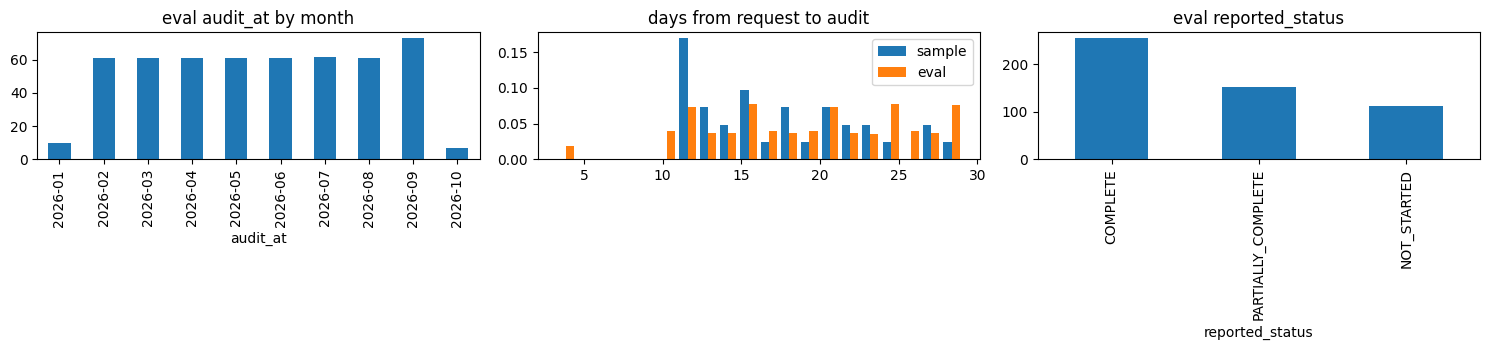

requested<=reported<=audit holds everywhere: True


In [31]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
pd.to_datetime(req.audit_at).dt.strftime('%Y-%m').value_counts().sort_index().plot.bar(ax=ax[0], title='eval audit_at by month')
gap = lambda x: (pd.to_datetime(x.audit_at) - pd.to_datetime(x.requested_at)).dt.total_seconds()/86400
ax[1].hist([gap(sreq), gap(req)], bins=20, label=['sample','eval'], density=True); ax[1].legend(); ax[1].set_title('days from request to audit')
req.reported_status.value_counts().plot.bar(ax=ax[2], title='eval reported_status')
plt.tight_layout(); plt.show()
print('requested<=reported<=audit holds everywhere:', ((req.requested_at<=req.reported_at)&(req.reported_at<=req.audit_at)).all())

## 9. Deviations and anomalies — summary

| # | Area | Observation | Impact on design |
|---|---|---|---|
| A1 | Output order | `deletion_requests.csv` is in **numeric** case order (`case_33…case_550`). A lexical sort would reorder it. | Emit rows in input-file order (numeric). **Decision to confirm.** |
| A2 | Status claims | `reported_status` disagrees with the truth in 22/32 samples. | Never use it as a signal. |
| A3 | Activity claims | Even `SUCCESS` DELETE, REDACT and ANONYMIZE rows can be contradicted by evidence. 721 FAILED and 376 PARTIAL rows. | State comes from evidence snapshots at or before `audit_at`, with activity as supporting context. |
| A4 | Activity ordering | Not time-sorted. Back-dated LINK_RESOURCE_IDENTITY rows sit at the end. | Sort by `event_time` and filter `<= audit_at`. |
| A5 | Identity | 19% of eval requests use a **historical** email. 20 emails are UPPERCASE. | Build an identifier set per user (all emails, hashes, phones, user_id) and match case-insensitively. |
| A6 | Decoys | 3 name collisions in identities. Evidence holds look-alike people (e.g. `Karim El-Masri` next to `Amina El-Masri`, `Mateo Rios Gil` next to `Mateo Ríos`). Resource-id numbers are not tied to user numbers. | Never match on name, fuzzy similarity or id-number coincidence. Match only on exact identifiers (emails, hash, phone, user_id). |
| A7 | Repeat subject | `user_18` has 2 eval cases with different `audit_at`. `user_07` and `user_17` appear in both the sample and eval sets. | Each case is evaluated independently at its own cut-off. |
| A8 | Intent | 10 non-deletion requests (`case_533–542`) use negation traps ("marketing lists **only**", "**not** a request to erase"). There are no NOT_APPLICABLE samples. | A dedicated intent classifier, either an LLM or rules plus an LLM, with our own test cases. |
| A9 | Languages | 62 non-English eval requests (pt 14, es 12, fr 12, ja 12, ko 12), each a single deletion template. | Multilingual intent handling. Cheap, because there are only 5 templates. |
| A14 | Activity coverage | 26 of 111 sample-answer resources never appear in `system_activity`. | Build the record inventory from evidence, not from activity. |
| A15 | Proof of absence | COMPLETE cases cite snapshots in which the record is *missing* (`evidence_54`). | The engine needs a "system snapshot covers this resource or user and it is absent" rule for citation. |
| A16 | Sample vs eval timing | Samples are audited late (Sep–Oct). Eval audits are spread Jan–Oct, with far fewer files available. | Rules learned on samples must generalise to earlier, sparser states. Our own test cases should cover early audits. |
| A10 | Request-text hints | Sample texts hint at scenarios. Eval texts are generic boilerplate. | Discovery must be evidence-driven, not text-driven. |
| A11 | Evidence time | Many files postdate a case's `audit_at`. | Hard filter `captured_at <= audit_at` for both state and citation. |
| A12 | Multimodal | Some users appear only in PNG or PDF evidence. | Extract PNG and PDF facts once with a vision LLM or OCR, cache them, and treat them as text. |
| A13 | Citations | The samples cite only `evidence_*` files, never activity or audit ids. | Default to file ids. Confirm whether activity or audit ids are ever expected. |

## 10. Implications for the design (to be discussed)
1. **Mostly deterministic core.** Identity resolution, time cut-off, rule application, step generation and ordering are rule-based and testable against the 32 samples.
2. **Narrow LLM use** (keeps `usage_report.md` small):
   * (a) intent classification of about 375 distinct texts (or about 27 templates), which can be cached;
   * (b) one-time structured extraction from 15 PNG and PDF files, which can be cached;
   * (c) optionally, categorising ambiguous evidence records into `data_category`.
3. **Evidence normalisation layer.** Parse SQL (by loading into SQLite), logs, JSON and TXT into a uniform `record(system_id, resource_id, user identifiers, fields present, captured_at, file_id)` table. Then per case: filter by identifier and time, take the latest state per resource, apply rules, and emit steps.
4. **Next step:** a deep-dive into evidence formats, working case by case through all 32 samples, to derive the exact mapping from evidence to findings, citations and system_ids before freezing the design.